In [1]:
# 1. Carga de librerías y datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

In [2]:
# Cargamos el dataset de Pima Indians Diabetes (UCI)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = ['Embarazos', 'Glucosa', 'PresionArterial', 'GrosorPiel', 'Insulina', 'IMC', 'FuncionPedigri', 'Edad', 'Resultado']
df = pd.read_csv(url, names=column_names)

In [3]:
print(df.head())

   Embarazos  Glucosa  PresionArterial  GrosorPiel  Insulina   IMC  \
0          6      148               72          35         0  33.6   
1          1       85               66          29         0  26.6   
2          8      183               64           0         0  23.3   
3          1       89               66          23        94  28.1   
4          0      137               40          35       168  43.1   

   FuncionPedigri  Edad  Resultado  
0           0.627    50          1  
1           0.351    31          0  
2           0.672    32          1  
3           0.167    21          0  
4           2.288    33          1  


In [4]:
# --- VISUALIZACIÓN AVANZADA ---

# A. Distribución de Glucosa (Histograma y Boxplot)
# Tal como indican las fuentes, el histograma permite ver la forma y el boxplot los atípicos [3].
fig = px.histogram(df, x="Glucosa", color="Resultado", marginal="box",
                   title="Distribución de Glucosa por Diagnóstico",
                   labels={'Resultado': 'Diabetes (1: Sí, 0: No)'},
                   template="plotly_white")
fig.show() # Esta gráfica es interactiva



In [5]:
# B. Relación entre IMC y Glucosa (Scatter Plot)
# Las fuentes señalan que el scatter plot ayuda a entender asociaciones entre variables [6].
fig2 = px.scatter(df, x="IMC", y="Glucosa", color="Resultado", trendline="ols",
                 title="Relación IMC vs Glucosa con Tendencia Lineal",
                 hover_data=['Edad'])
fig2.show()

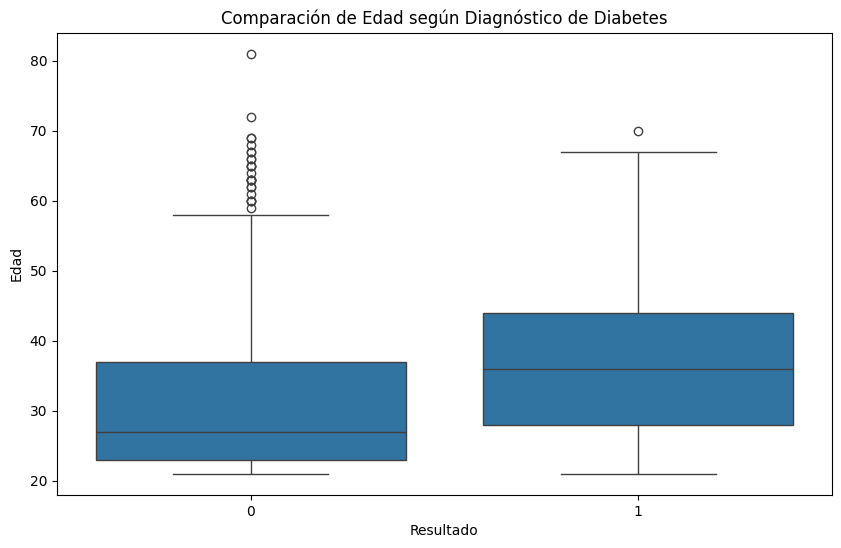

In [6]:
# C. Comparación de Grupos (Boxplots por categoría)
# Útil para visualizar diferencias que luego evaluaremos estadísticamente [4].
plt.figure(figsize=(10, 6))
sns.boxplot(x='Resultado', y='Edad', data=df)
plt.title('Comparación de Edad según Diagnóstico de Diabetes')
plt.show()


In [7]:
# --- INFERENCIA ESTADÍSTICA ---

# Las fuentes definen la inferencia como el paso para sacar conclusiones poblacionales [7].
# Realizaremos una Prueba T para ver si la media de Glucosa es significativamente
# diferente entre personas con y sin diabetes.

# H0: No hay diferencia de glucosa entre grupos.
# H1: Hay diferencia significativa [8].

grupo_sano = df[df['Resultado'] == 0]['Glucosa']
grupo_diabetico = df[df['Resultado'] == 1]['Glucosa']

t_stat, p_val = stats.ttest_ind(grupo_sano, grupo_diabetico)

print(f"--- Resultados de la Inferencia ---")
print(f"Valor p (p-value): {p_val:.10f}")

# Interpretación según las fuentes: p < 0.05 indica evidencia contra la H0 [5].
if p_val < 0.05:
    print("Conclusión: Existe una diferencia estadísticamente significativa en los niveles de glucosa.")
else:
    print("Conclusión: No hay evidencia suficiente para afirmar una diferencia.")

--- Resultados de la Inferencia ---
Valor p (p-value): 0.0000000000
Conclusión: Existe una diferencia estadísticamente significativa en los niveles de glucosa.
